In [79]:
import pandas as pd

df = pd.read_csv("student_clustering.csv")
df

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110
...,...,...
195,4.68,89
196,8.57,118
197,5.85,112
198,6.23,108


In [80]:
x = df[["cgpa", "iq"]]
x

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110
...,...,...
195,4.68,89
196,8.57,118
197,5.85,112
198,6.23,108


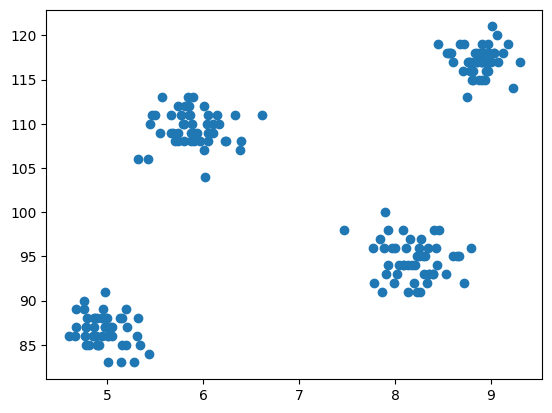

In [81]:
import matplotlib.pyplot as plt
plt.scatter(x['cgpa'], x['iq'])


In [83]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)
df_scaled = pd.DataFrame(x_scaled, columns=x.columns)
df_scaled
x = df_scaled[["cgpa", "iq"]]
x

,cgpa,iq
0,0.112766,0.131579
1,0.276596,0.789474
2,0.800000,0.263158
3,0.780851,0.368421
4,0.180851,0.710526
...,...,...
195,0.017021,0.157895
196,0.844681,0.921053
197,0.265957,0.763158
198,0.346809,0.657895


Text(0.5, 1.0, 'Elbow Method')

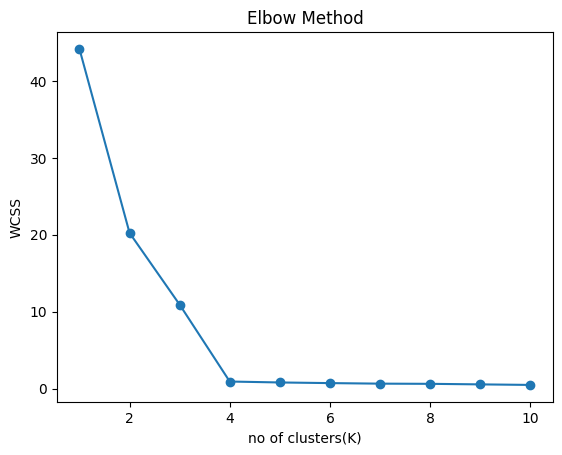

In [84]:
from sklearn.cluster import KMeans

wcss = []
for i in range(1,11):
  kmeans = KMeans(n_clusters=i, random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("no of clusters(K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")


In [85]:
kmean = KMeans(n_clusters=4, random_state=42)
y_pred = kmean.fit_predict(x_scaled)
y_pred

array([3, 0, 2, 2, 0, 0, 2, 1, 0, 2, 3, 0, 2, 3, 0, 2, 0, 2, 0, 0, 2, 3,
       2, 3, 3, 2, 3, 1, 2, 0, 1, 0, 1, 0, 2, 2, 1, 0, 3, 0, 3, 2, 2, 3,
       1, 1, 2, 0, 1, 0, 3, 3, 1, 2, 1, 0, 0, 1, 0, 1, 0, 2, 2, 1, 3, 1,
       2, 3, 0, 2, 0, 1, 2, 3, 0, 1, 0, 1, 3, 2, 2, 1, 0, 3, 1, 3, 1, 0,
       1, 0, 1, 1, 2, 3, 2, 2, 1, 2, 3, 1, 0, 3, 3, 1, 3, 3, 2, 3, 1, 1,
       2, 1, 0, 0, 2, 1, 2, 0, 1, 3, 3, 0, 2, 1, 2, 3, 2, 0, 3, 2, 2, 0,
       3, 3, 0, 1, 0, 3, 2, 2, 2, 3, 0, 3, 3, 1, 3, 1, 0, 3, 1, 3, 1, 1,
       3, 2, 0, 1, 0, 2, 3, 1, 0, 2, 1, 3, 0, 3, 3, 1, 1, 0, 1, 3, 3, 2,
       1, 0, 3, 1, 1, 0, 0, 0, 2, 3, 2, 2, 1, 0, 2, 2, 3, 3, 2, 3, 1, 0,
       0, 1], dtype=int32)

In [86]:
df_scaled["Cluster"] = y_pred
df

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110
...,...,...
195,4.68,89
196,8.57,118
197,5.85,112
198,6.23,108


In [87]:
df1 = df_scaled[df_scaled["Cluster"] == 0]
df2 = df_scaled[df_scaled["Cluster"] == 1]
df3 = df_scaled[df_scaled["Cluster"] == 2]
df4 = df_scaled[df_scaled["Cluster"] == 3]
df4

,cgpa,iq,Cluster
0,0.112766,0.131579,3
10,0.000000,0.078947,3
13,0.085106,0.131579,3
21,0.055319,0.078947,3
23,0.038298,0.105263,3
24,0.076596,0.131579,3
26,0.055319,0.105263,3
38,0.178723,0.026316,3
40,0.157447,0.052632,3
43,0.151064,0.078947,3


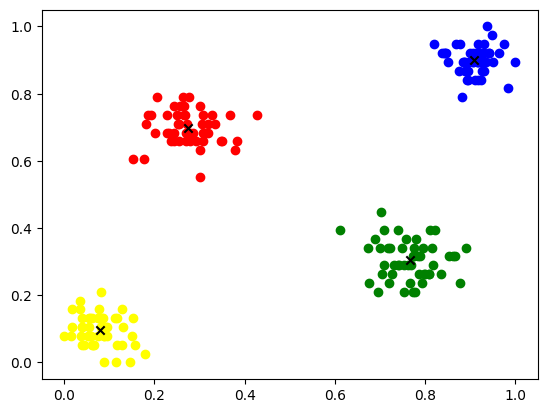

In [88]:
plt.scatter(df1["cgpa"], df1["iq"], color="red", label="Cluster 1")
plt.scatter(df2["cgpa"], df2["iq"], color="blue", label="Cluster 2")
plt.scatter(df3["cgpa"], df3["iq"], color="green", label="Cluster 3")
plt.scatter(df4["cgpa"], df4["iq"], color="Yellow", label="Cluster 4")

plt.scatter(kmean.cluster_centers_[:,0],kmean.cluster_centers_[:,1],color="black", marker="x",label='Centroids')